# Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the dataset

In [2]:
iris = load_iris()

# Use two classes for binary classification
X = iris.data[:100, :2]
y = iris.target[:100]

print("Features:", iris.feature_names[:2])
print("Classes:", iris.target_names[:2])
print("Dataset shape:", X.shape)

Features: ['sepal length (cm)', 'sepal width (cm)']
Classes: ['setosa' 'versicolor']
Dataset shape: (100, 2)


# Split and normalize the data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


# Build and train the single-layer neural network

In [4]:
model = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42
)

model.fit(X_train, y_train)

print("Single-layer Perceptron trained successfully!")

Single-layer Perceptron trained successfully!


# Make predictions

In [5]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred
})

print("Classification Results:")
display(results)

Classification Results:


,Actual Class,Predicted Class
0,1,0
1,1,1
2,1,1
3,1,1
4,0,0
5,0,0
6,0,0
7,1,1
8,0,1
9,0,0


# Evaluate the model

In [6]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names[:2],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       0.90      0.90      0.90        10
  versicolor       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20

Confusion Matrix:
[[9 1]
 [1 9]]


# Visualize the classification

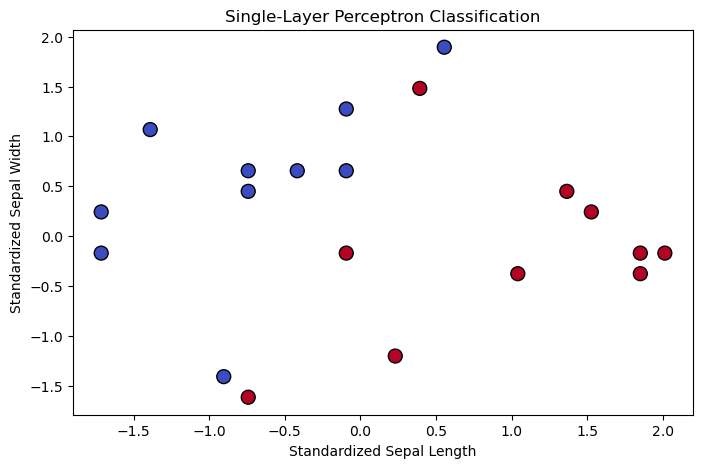

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_pred,
    cmap="coolwarm",
    s=100,
    edgecolors="black"
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("Single-Layer Perceptron Classification")
plt.show()